# Initial Exploratory Data Analysis

## Project: Predicting Successful NFL Third Down Conversions

This project examines NFLverse play-by-play data from the 2023-2026 seasons. The goal is to identify pre-play factors associated with successful third down conversions, including yards to go, field position, quarter, score differential, play type, formation and time remaining.

**Data Source:** [NFLverse Play-by-Play Data](https://github.com/nflverse/nflverse-data/releases/tag/pbp)

In [231]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


url_2023 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2023.parquet")
url_2024 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2024.parquet")
url_2025 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2025.parquet")
url_2026 = ("https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2026.parquet")

pbp_2023 = pd.read_parquet(url_2023)
pbp_2024 = pd.read_parquet(url_2024)
pbp_2025 = pd.read_parquet(url_2025)
pbp_2026 = pd.read_parquet(url_2026)

pbp = pd.concat([pbp_2023, pbp_2024, pbp_2025, pbp_2026], ignore_index=True)

pbp.head(5)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,NaN,NaN,NaN,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0.0,1.0,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


In [232]:
print(f"Total: {pbp.shape[0]:,} rows, {pbp.shape[1]:,} columns\n")
print(f"Dataset: {pbp.shape[0]:,} plays from 2023-2026 seasons\n")
pbp["season"].value_counts().sort_index()

Total: 161,770 rows, 372 columns

Dataset: 161,770 plays from 2023-2026 seasons



season
2023    49665
2024    49492
2025    48771
2026    13842
Name: count, dtype: int64

In [233]:
pbp.info()

<class 'pandas.DataFrame'>
RangeIndex: 161770 entries, 0 to 161769
Columns: 372 entries, play_id to pass_oe
dtypes: float64(200), int32(7), str(165)
memory usage: 548.9 MB


In [234]:
pbp.describe()

,play_id,week,yardline_100,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,quarter_end,drive,sp,qtr,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
count,161770.000000,161770.000000,150233.000000,161753.000000,161753.000000,161753.000000,161770.000000,159917.000000,161770.000000,161770.000000,...,161770.000000,161770.000000,159902.000000,54707.000000,54707.000000,54707.000000,54707.000000,54707.000000,123225.000000,119667.000000
mean,2189.862094,9.358101,47.735704,408.822439,802.823169,1703.229344,0.017642,11.332104,0.075478,2.568084,...,0.085918,0.503808,0.007007,0.733384,5.527644,3.703274,0.775783,0.578705,0.628940,-1.406847
std,1275.946418,5.713207,23.935202,283.000330,561.045785,1058.487010,0.131648,6.596146,0.264161,1.129737,...,0.280244,0.499987,1.248266,0.528071,2.563775,2.630557,0.254205,0.357054,0.241020,42.367780
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,-12.689102,-3.181688,0.442673,0.000000,0.026981,0.004220,0.013008,-99.538189
25%,1094.000000,4.000000,30.000000,143.000000,273.000000,780.000000,0.000000,6.000000,0.000000,2.000000,...,0.000000,0.000000,-0.557885,0.325700,3.755751,2.000000,0.555580,0.242589,0.456088,-42.547296
50%,2169.000000,9.000000,49.000000,388.000000,784.000000,1800.000000,0.000000,11.000000,0.000000,2.000000,...,0.000000,1.000000,0.000000,0.608661,4.621189,3.000000,0.983191,0.474718,0.601598,3.849614
75%,3268.000000,14.000000,68.000000,654.000000,1284.000000,2589.000000,0.000000,17.000000,0.000000,4.000000,...,0.000000,1.000000,0.532200,1.007454,6.924437,5.000000,1.000000,0.999327,0.859592,32.892758
max,5519.000000,22.000000,99.000000,900.000000,1800.000000,3600.000000,1.000000,34.000000,1.000000,5.000000,...,1.000000,1.000000,8.882384,9.585749,23.952005,36.000000,1.000000,1.000000,0.997794,97.848164


In [235]:
pbp.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [236]:
#Looking for Missing Values
pbp.isnull().sum()

play_id                     0
game_id                     0
old_game_id                 0
home_team                   0
away_team                   0
                        ...  
xyac_median_yardage    107063
xyac_success           107063
xyac_fd                107063
xpass                   38545
pass_oe                 42103
Length: 372, dtype: int64

In [237]:
# Checking for Duplicate Values
print(f"Number of Duplicate Values: {pbp.duplicated().sum()}")

Number of Duplicate Values: 0


In [238]:
# Creating a new dataframe of only 3rd Down Plays
third_down = pbp[pbp["down"] == 3].copy()

print(f"Dataset: {third_down.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 26,343 third down plays from 2023-2026 seasons



In [239]:
# Reviewing the types of third down plays
third_down['play_type'].value_counts(dropna=False)

play_type
pass          17806
run            5957
no_play        2251
qb_kneel        198
field_goal      104
qb_spike         27
Name: count, dtype: int64

In [240]:
# Reviewing the target variable
third_down['third_down_converted'].value_counts(dropna=False)

third_down_converted
0.0    16869
1.0     9433
NaN       41
Name: count, dtype: int64

In [241]:
# Reviewing regular season vs playoffs
third_down['season_type'].value_counts(dropna=False)

season_type
REG     25265
POST     1078
Name: count, dtype: int64

In [242]:
# Keeping regular season third down attempts. This removes QB kneels, no_play, field goal attempts that were not intended to convert the third down.
third_down_analysis = third_down[
    (third_down['season_type'] == 'REG') &
    (third_down['play_type'].isin (['run','pass'])) &
    (third_down['third_down_converted'].notna())
].copy()

print(f"Dataset: {third_down_analysis.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 22,766 third down plays from 2023-2026 seasons



In [243]:
analysis_columns = [
    "game_id",
    "play_id",
    "season",
    "week",
    "posteam",
    "defteam",
    "qtr",
    "game_seconds_remaining",
    "yardline_100",
    "ydstogo",
    "play_type",
    "third_down_converted",
    "posteam_timeouts_remaining",
    "defteam_timeouts_remaining",
    "score_differential",
    "shotgun"
]
third_down_plays = third_down_analysis[analysis_columns].copy()
third_down_plays.shape

(22766, 16)

In [244]:
# Looking for missing values in the selected analysis variables

missing_values = pd.DataFrame({
    "missing_count": third_down_plays.isna().sum(),
    "missing_percentage": third_down_plays.isna().mean() * 100
})

missing_values.sort_values(by="missing_percentage", ascending=False)
missing_values

,missing_count,missing_percentage
game_id,0,0.0
play_id,0,0.0
season,0,0.0
week,0,0.0
posteam,0,0.0
defteam,0,0.0
qtr,0,0.0
game_seconds_remaining,0,0.0
yardline_100,0,0.0
ydstogo,0,0.0


In [245]:
print("Complete Duplicate Rows:", third_down_plays.duplicated().sum())
print("Duplicate Rows by Play ID:", third_down_plays.duplicated(subset=["game_id", "play_id"]).sum())

Complete Duplicate Rows: 0
Duplicate Rows by Play ID: 0


In [246]:
conversion_summary = (third_down_plays["third_down_converted"].value_counts().reindex([0, 1], fill_value=0).rename_axis("conversion").reset_index(name="count"))

# Adding Descriptive Labels
conversion_summary["outcome"] = conversion_summary["conversion"].map({0: "Failed", 1: "Successful"})

# Calculating the proportion and percentage of third down plays
conversion_summary["rate"] = (conversion_summary["count"] / conversion_summary["count"].sum())

conversion_summary["rate_percentage"] = (conversion_summary["rate"] * 100).round(2).astype(str) + "%"

# Renaming Column Names to be more descriptive
conversion_summary = conversion_summary[["outcome", "count", "rate_percentage"]].rename(columns={
    "outcome": "Conversion Outcome",
    "count": "Number of Plays",
    "rate_percentage": "Percentage of Plays"
})

print(conversion_summary)


  Conversion Outcome  Number of Plays Percentage of Plays
0             Failed            13745              60.38%
1         Successful             9021              39.62%


In [247]:
# Comparing Conversion Rates by Seasons
conversion_by_season = (third_down_plays.groupby("season", as_index=False)
.agg(
    number_of_plays = ("third_down_converted", "count"),
    successful_conversions = ("third_down_converted", "sum"),
    conversion_rate = ("third_down_converted", "mean")
))

# Converting Rate to Percentage
conversion_by_season["conversion_rate"] = (conversion_by_season["conversion_rate"] * 100).round(2).astype(str) + "%"

# Renaming Columns
conversion_by_season = conversion_by_season.rename(columns={
    "season": "Season",
    "number_of_plays": "Number of Plays",
    "successful_conversions": "Successful Conversions",
    "conversion_rate": "Conversion Rate (%)"
})

conversion_by_season.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}",
})

,Season,Number of Plays,Successful Conversions,Conversion Rate (%)
0,2023,"7,140","2,788",39.05%
1,2024,"6,828","2,728",39.95%
2,2025,"6,801","2,710",39.85%
3,2026,"1,997",795,39.81%


In [248]:
def summarize_conversions(data, group_column):
    summary = (
        data.groupby(group_column, as_index=False).agg(
            number_of_plays=(
                "third_down_converted", "count"
            ),
            successful_conversions=(
                "third_down_converted", "sum"
            ),
            conversion_rate=(
                "third_down_converted", "mean"
            )
        )
    )
    summary["conversion_rate"] = (summary["conversion_rate"] * 100).round(2)

    return summary

In [249]:
conversion_by_play_type = summarize_conversions(third_down_plays, "play_type")

conversion_by_play_type_display = conversion_by_play_type.rename(
    columns={
        "play_type": "Play Type",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
).copy()

conversion_by_play_type_display['Play Type'] = (conversion_by_play_type_display['Play Type'].str.title())
conversion_by_play_type_display['Conversion Rate (%)'] = (conversion_by_play_type_display['Conversion Rate (%)'].astype(str) + "%")

conversion_by_play_type_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Play Type,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Pass,"17,081","5,990",35.07%
1,Run,"5,685","3,031",53.32%


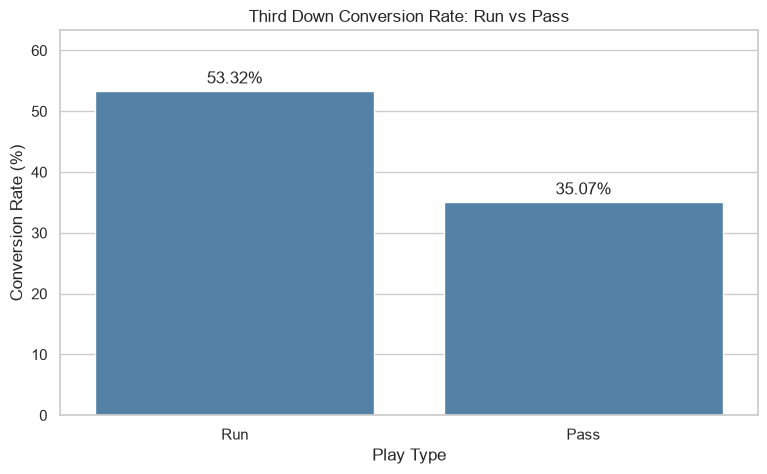

In [250]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=conversion_by_play_type,
    x = conversion_by_play_type["play_type"].str.title(),
    y = "conversion_rate",
    order = ["Run", "Pass"],
    color = "steelblue"
)

plt.title("Third Down Conversion Rate: Run vs Pass")
plt.xlabel("Play Type")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, conversion_by_play_type["conversion_rate"].max() + 10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.show()

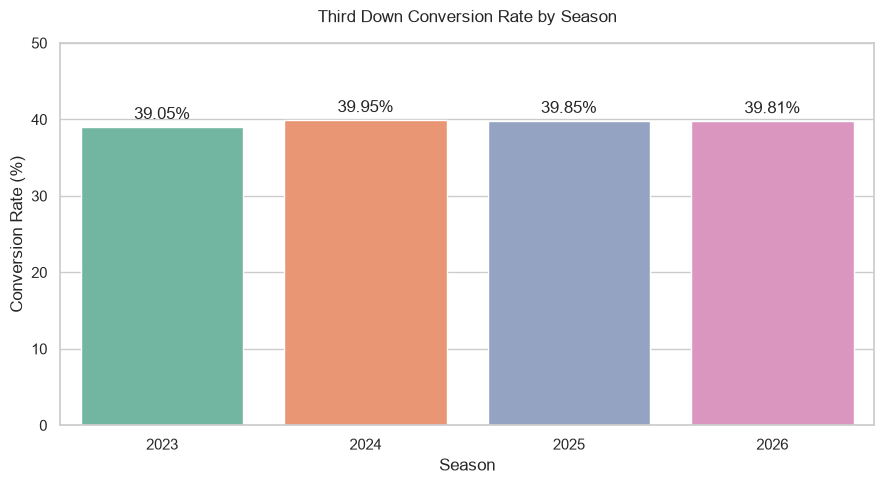

In [251]:
sns.set_theme(style="whitegrid")

season_plot = (third_down_plays.groupby("season", as_index=False)["third_down_converted"].mean())

season_plot["conversion_rate"] = season_plot["third_down_converted"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=season_plot,
    x="season",
    y="conversion_rate",
    hue="season",
    palette="Set2",
    dodge=False,
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

ax.set_title("Third Down Conversion Rate by Season", pad=15)
ax.set_xlabel("Season")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, 50)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [252]:
third_down_plays["yards_to_go_group"] = pd.cut(third_down_plays["ydstogo"], 
    bins=[0, 2, 5, 10, np.inf], 
    labels=[
        "1-2 Yards",
        "3-5 Yards",
        "6-10 Yards",
        "11+ Yards"
    ]
)

conversion_by_distance = summarize_conversions(third_down_plays, "yards_to_go_group")

conversion_by_distance_display = conversion_by_distance.rename(
    columns={
        "yards_to_go_group": "Yards to Go",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

# Display successful conversion counts as whole numbers
conversion_by_distance_display["Successful Conversions"] = (
    conversion_by_distance_display["Successful Conversions"].astype(int)
)
conversion_by_distance_display['Conversion Rate (%)'] = (conversion_by_distance_display['Conversion Rate (%)'].astype(str) + "%")


conversion_by_distance_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Yards to Go,Number of Plays,Successful Conversions,Conversion Rate (%)
0,1-2 Yards,"4,677","2,971",63.52%
1,3-5 Yards,"5,690","2,679",47.08%
2,6-10 Yards,"8,154","2,731",33.49%
3,11+ Yards,"4,245",640,15.08%


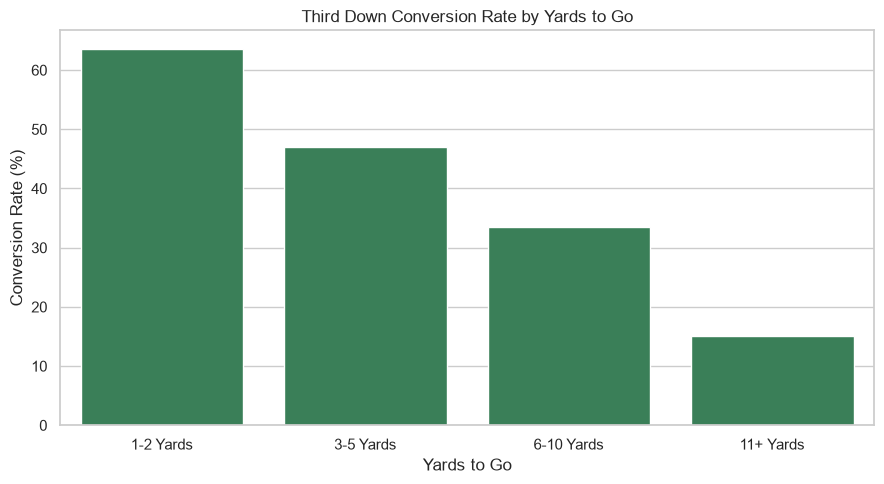

In [253]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data = conversion_by_distance,
    x = conversion_by_distance["yards_to_go_group"].str.title(),
    y = "conversion_rate",
    color = "seagreen"
)

plt.title("Third Down Conversion Rate by Yards to Go")
plt.xlabel("Yards to Go")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

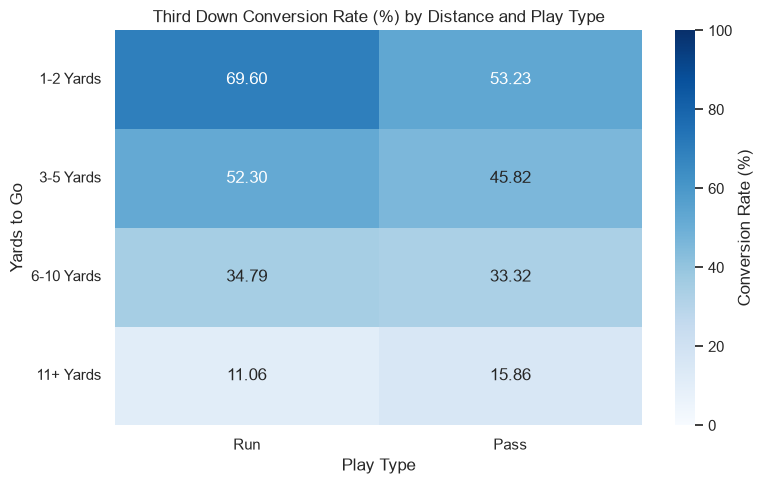

In [254]:
conversion_heatmap = third_down_plays.pivot_table(
    values="third_down_converted",
    index="yards_to_go_group",
    columns="play_type",
    aggfunc="mean",
    observed=False
) * 100

conversion_heatmap = conversion_heatmap.reindex(columns=["run", "pass"])
conversion_heatmap = conversion_heatmap.rename(columns={"run": "Run", "pass": "Pass"})

plt.figure(figsize=(8, 5))
sns.heatmap(
    conversion_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Conversion Rate (%)"}
)

plt.title("Third Down Conversion Rate (%) by Distance and Play Type")
plt.xlabel("Play Type")
plt.ylabel("Yards to Go")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [255]:
conversion_by_quarter = summarize_conversions(third_down_plays, "qtr")

conversion_by_quarter_display = conversion_by_quarter.rename(
    columns={
        "qtr": "Quarter",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

# Display successful conversion counts as whole numbers
conversion_by_quarter_display["Successful Conversions"] = (
    conversion_by_quarter_display["Successful Conversions"].astype(int)
)

# Display quarters as whole numbers
conversion_by_quarter_display["Quarter"] = (
    conversion_by_quarter_display["Quarter"].astype(int)
)

# Display conversion rate with a percentage sign
conversion_by_quarter_display['Conversion Rate (%)'] = (conversion_by_quarter_display['Conversion Rate (%)'].astype(str) + "%")

# Display quarter 5 as Overtime
conversion_by_quarter_display["Quarter"] = (
    conversion_by_quarter_display["Quarter"].replace({5: "Overtime"})
)

conversion_by_quarter_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Quarter,Number of Plays,Successful Conversions,Conversion Rate (%)
0,1,"5,067","2,089",41.23%
1,2,"6,288","2,485",39.52%
2,3,"4,980","1,999",40.14%
3,4,"6,317","2,400",37.99%
4,Overtime,114,48,42.11%


In [256]:
third_down_plays["field_position_group"] = pd.cut(
    third_down_plays["yardline_100"],
    bins=[0, 20, 50, 80, 100],
    labels=[
        "Opponent 1-20",
        "Opponent 21-50",
        "Own 21-50",
        "Own 1-20"
    ],
    include_lowest=True
)

conversion_by_field_position = summarize_conversions(third_down_plays, "field_position_group")

conversion_by_field_position_display = conversion_by_field_position.rename(
    columns={
        "field_position_group": "Field Position",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

conversion_by_field_position_display['Conversion Rate (%)'] = (conversion_by_field_position_display['Conversion Rate (%)'].astype(str) + "%")

conversion_by_field_position_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Field Position,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Opponent 1-20,"3,815","1,526",40.0%
1,Opponent 21-50,"7,275","2,985",41.03%
2,Own 21-50,"9,968","3,989",40.02%
3,Own 1-20,"1,708",521,30.5%


In [257]:
third_down_plays["score_situation"] = pd.cut(
    third_down_plays["score_differential"],
    bins = [-np.inf, -9, -1, 0, 8, np.inf],
    labels = [
        "Trailing by 9+",
        "Trailing by 1-8",
        "Tied",
        "Leading by 1-8",
        "Leading by 9+"
    ]
)

conversion_by_score = summarize_conversions(third_down_plays, "score_situation")

conversion_by_score_display = conversion_by_score.rename(
    columns={
        "score_situation": "Score Situation",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

conversion_by_score_display['Conversion Rate (%)'] = (conversion_by_score_display['Conversion Rate (%)'].astype(str) + "%")

conversion_by_score_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Score Situation,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Trailing by 9+,"4,358","1,668",38.27%
1,Trailing by 1-8,"6,188","2,457",39.71%
2,Tied,"4,475","1,827",40.83%
3,Leading by 1-8,"4,773","1,873",39.24%
4,Leading by 9+,"2,972","1,196",40.24%
